# TCC — Classificação de Surtos Atmosféricos com TinyML
Sistema Embarcado Baseado em TinyML para Classificação de Sinais de Surtos Atmosféricos em Redes de Distribuição Elétrica

**Como usar:** rode as células na ordem (Ambiente de execução → Executar tudo).
Os scripts `.py` ficam na pasta `TCC_Surtos` do Google Drive. Os dados são sintéticos (simulação RLC + impulso 1,2/50 µs).

## 0. Configuração — conecta o Drive e restaura os arquivos

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os, shutil
PASTA = '/content/drive/MyDrive/TCC_Surtos'
os.makedirs(PASTA, exist_ok=True)

# Traz só os scripts do Drive. Os dados são regenerados nas etapas 1 e 2 (semente fixa = mesmo resultado).
for arq in ['tcc_simulacao_v2.py', 'tcc_augmentation_3classes.py',
            'tcc_pipeline_3classes_v2.py', 'tcc_exportar_tflite_3classes.py',
            'tcc_validar_inferencia_int8.py', 'tcc_teste_robustez.py', 'tcc_robustez_multisementes.py']:
    shutil.copy(f'{PASTA}/{arq}', '.')
    print('✓', arq)

Mounted at /content/drive
✓ tcc_simulacao_v2.py
✓ tcc_augmentation_3classes.py
✓ tcc_pipeline_3classes_v2.py
✓ tcc_exportar_tflite_3classes.py
✓ tcc_validar_inferencia_int8.py
✓ tcc_teste_robustez.py
✓ tcc_robustez_multisementes.py


## 1. Simulação do circuito RLC e verificação do impulso (IEC 60060-1)

  TCC — Simulação de Surtos Atmosféricos v2 (corrigida)

  Circuito: R=450.1 Ω | L=0.1093 H | C=1.27e-07 F
  Impulso:  alfa=14286 s⁻¹ | beta=2.16e+06 s⁻¹
  Tempo:    passo=100 ns | janela=200 µs

[0] Simulando cenário NORMAL...
    RMS na carga: 21.01 V

[1] Simulando cenário SURTO LEVE...
    Pico do impulso: 39.03 kV
    Pico na carga:   667.64 V

[2] Simulando cenário SURTO SEVERO...
    Pico do impulso: 97.58 kV
    Pico na carga:   1652.97 V

[3] Verificando parâmetros do impulso...
    Frente (T1): 1.33 µs  (norma: 1,2 µs ± 30% → 0,84 a 1,56)
    Cauda  (T2): 51.40 µs  (norma: 50 µs ± 20% → 40 a 60)
    Resultado: ✓ APROVADO — dentro da IEC 60060-1


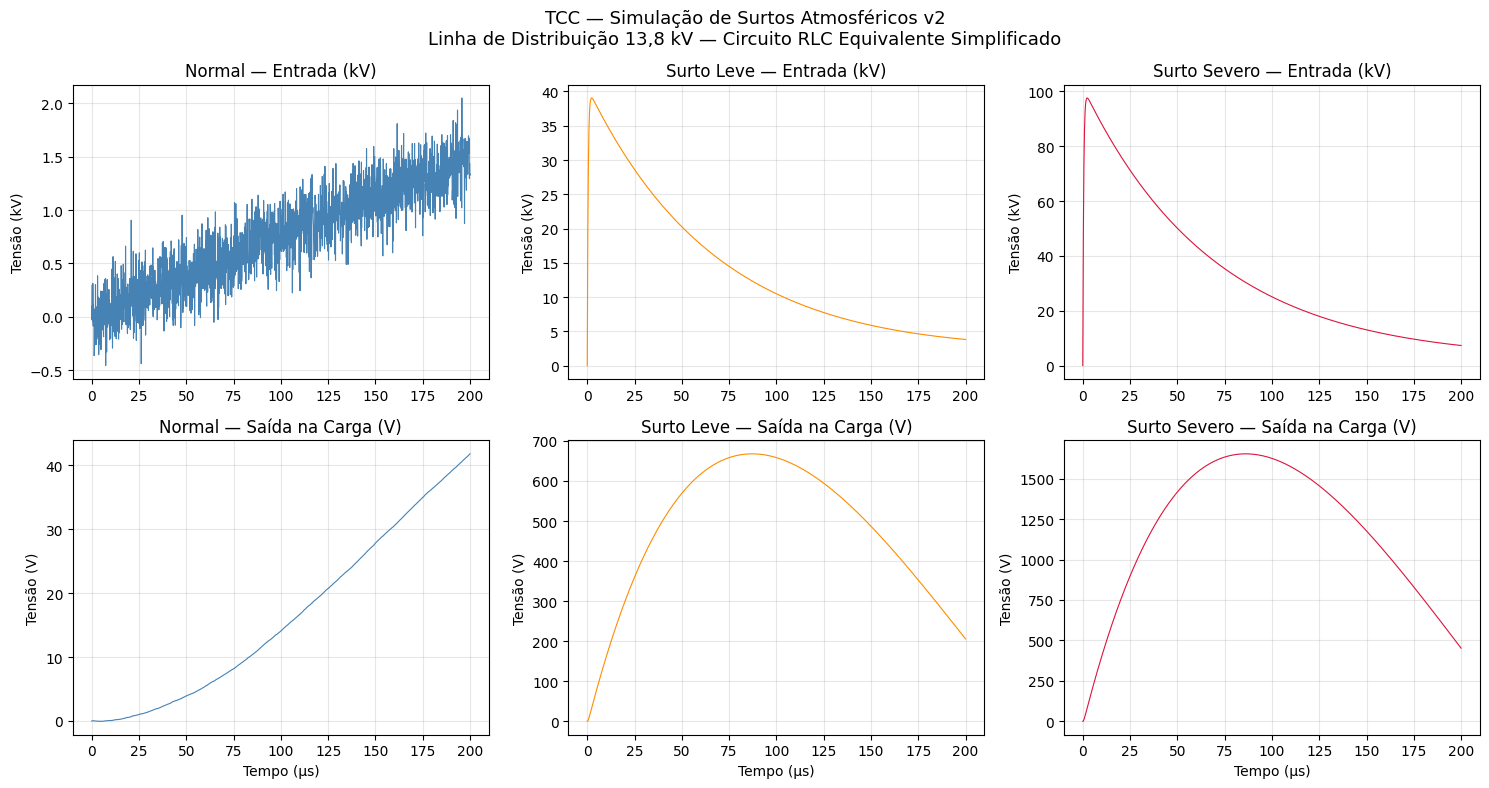


[4] Gráfico salvo em 'simulacao_v2.png'
[5] Dados exportados:
    ├── dados_simulacao_v2.npz  → uso no Colab (próximo passo)
    └── dados_simulacao_v2.mat  → compatível com MATLAB

✓ Passo 1 concluído! Rode agora o tcc_augmentation_3classes.py


In [ ]:
exec(open('tcc_simulacao_v2.py').read())

## 2. Data augmentation — 1500 exemplos (500 por classe)

  TCC — Data Augmentation — 3 Classes

  Gerando 500 exemplos × 3 classes = 1500 total
  Amostras por janela: 2001

[1] Gerando Classe 0 — Normal...
    ✓ 500 exemplos gerados
[2] Gerando Classe 1 — Surto Leve...
    ✓ 500 exemplos gerados
[3] Gerando Classe 2 — Surto Severo...
    ✓ 500 exemplos gerados

[4] Dataset final:
    Shape: (1500, 2001)  →  1500 janelas × 2001 amostras
    Classe 0 (Normal):       500 exemplos
    Classe 1 (Surto Leve):   500 exemplos
    Classe 2 (Surto Severo): 500 exemplos


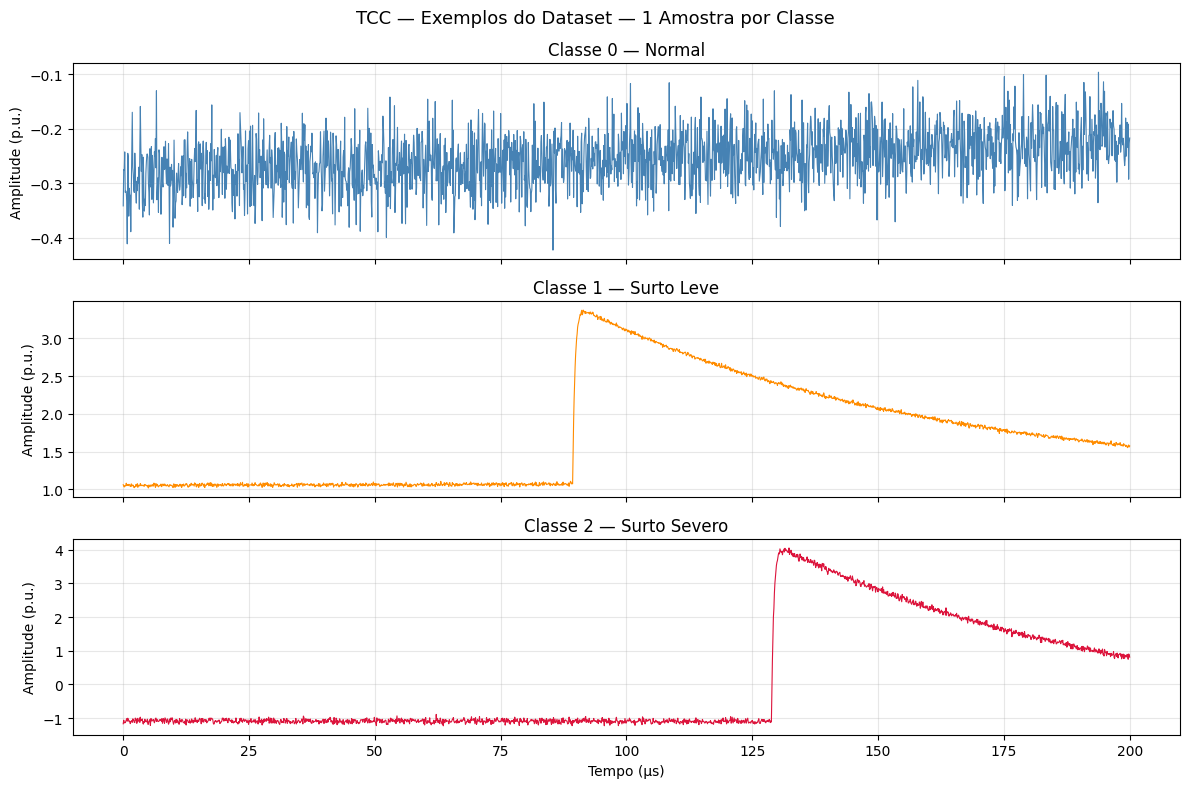


[5] Gráfico salvo em 'exemplos_3classes.png'
[6] Dataset salvo em 'dados_augmentados_3classes.npz'

✓ Passo 2 concluído!
  Próximo passo: rode tcc_pipeline_3classes.py para treinar o modelo


In [ ]:
exec(open('tcc_augmentation_3classes.py').read())

## 3. Pipeline de ML — extração de 8 features, Random Forest e K-Fold

  TCC — Pipeline v2 — Features Corrigidas — 3 Classes

[1] Carregando dados...
    Sinais: 1500 janelas × 2001 amostras
    Taxa de amostragem: 10 MHz
    Resolução da FFT:   5.0 kHz por bin
    Classe 0 (Normal):       500 exemplos
    Classe 1 (Surto Leve):   500 exemplos
    Classe 2 (Surto Severo): 500 exemplos

[2] Extraindo features corrigidas — aguarde...
    Features extraídas: (1500, 8)  →  8 números por sinal
    Features: ['RMS', 'Pico', 'Fator_Crista', 'Desvio_Padrao', 'Prop_HF_100kHz', 'Centroide', 'Freq_Dom_10kHz', 'Entropia']

[3] Treinando Random Forest — 3 classes...

── Relatório de Classificação ─────────────────────────────
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00       100
  Surto Leve       0.97      0.96      0.96       100
Surto Severo       0.96      0.97      0.97       100

    accuracy                           0.98       300
   macro avg       0.98      0.98      0.98       300
weighted avg       0.9

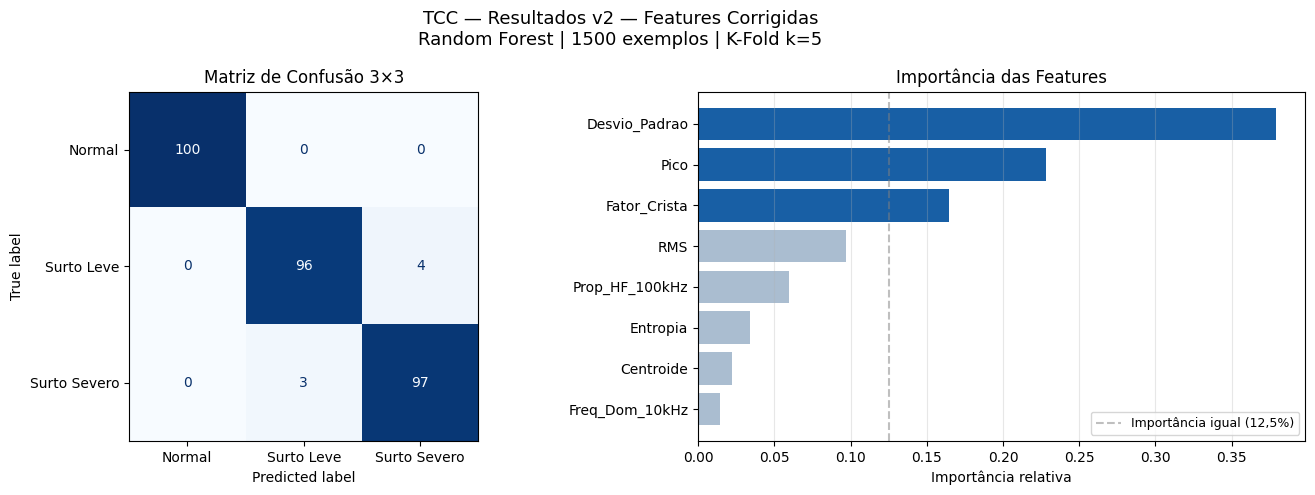


[5] Gráfico salvo em 'resultados_v2.png'
[6] Arquivos salvos:
    ├── modelo_3classes_v2.pkl
    ├── normalizacao_3classes_v2.npz
    └── resultados_v2.png

✓ Pipeline v2 concluído!
  Próximo: tcc_exportar_tflite_3classes.py


In [ ]:
exec(open('tcc_pipeline_3classes_v2.py').read())

## 4. Exportação TFLite INT8 e geração do `model.h` para o ESP32-S3

In [ ]:
exec(open('tcc_exportar_tflite_3classes.py').read())

[1] Extraindo features...
[2] Treino 900 | Validação 300 | Teste 300
[4] MLP float32 — acurácia no teste: 98.7%  (Random Forest: 99.0%)
Saved artifact at '/tmp/tmpn879kd5b'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 8), dtype=tf.float32, name='keras_tensor')
Output Type:
  TensorSpec(shape=(None, 3), dtype=tf.float32, name=None)
Captures:
  134098189690320: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134097890058384: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134097890058000: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134097890058768: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134097890058576: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134097890058192: TensorSpec(shape=(), dtype=tf.resource, name=None)
[5] TFLite INT8 — acurácia no teste: 98.3%  | tamanho: 3.47 KB

Relatório (modelo INT8):
              precision    recall  f1-score   support

      Normal      1.000   

## 5. Teste de robustez fora da distribuição de treino

In [ ]:
import os, shutil
for arq in ['tcc_teste_robustez.py', 'model.h',
            'detector_surtos_int8.tflite', 'dados_augmentados_3classes.npz']:
    if not os.path.exists(arq):
        shutil.copy(f'{PASTA}/{arq}', '.')
exec(open('tcc_teste_robustez.py').read())

Treino: 900 sinais | Teste: 300 sinais novos por cenário (100 por classe)

Cenário                                         Random Forest  INT8 (model.h)
A  Controle (mesma distribuição)                        98.0%           98.0%
B  Ruído maior (0,10 a 0,20)                            97.0%           98.7%
C  Amplitude da senoide fora da faixa                   97.0%           98.0%
D  Impulso nas bordas da janela                         95.3%           95.3%
E  Forma do impulso diferente (0,6x a 1,4x)             97.0%           97.7%
F  Harmônicos de 3a e 5a ordem                          98.7%           98.0%
G  B + C + D + E juntos                                 97.3%           96.7%

Matrizes de confusão do INT8 (linha = real, coluna = previsto):

Cenário B:
[[100   0   0]
 [  0  99   1]
 [  0   3  97]]

Cenário G:
[[100   0   0]
 [  0  97   3]
 [  0   7  93]]

Arquivos: robustez_resultados.png | robustez_resultados.md


## 6. Robustez com 10 sementes (média e desvio)

In [ ]:
for arq in ['dados_augmentados_3classes.npz']:
    if not os.path.exists(arq):
        shutil.copy(f'{PASTA}/{arq}', '.')
exec(open('tcc_robustez_multisementes.py').read())

Gerando os cenários de teste (uma vez, iguais para todas as sementes)...

Treinando e avaliando 10 sementes...
Saved artifact at '/tmp/tmpe2s8a567'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 8), dtype=tf.float32, name='keras_tensor')
Output Type:
  TensorSpec(shape=(None, 3), dtype=tf.float32, name=None)
Captures:
  133173811644560: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133173811642448: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133173811643024: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133173811649744: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133173811649360: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133173811642640: TensorSpec(shape=(), dtype=tf.resource, name=None)
  semente 0: controle INT8 97.3% | ruído maior 98.3% | B+C+D+E 94.7%
Saved artifact at '/tmp/tmplzjl088j'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): T

## 7. Salvar resultados no Drive

In [ ]:
for arq in ['dados_simulacao_v2.npz', 'dados_augmentados_3classes.npz',
            'modelo_3classes_v2.pkl', 'normalizacao_3classes_v2.npz',
            'normalizacao_tflite.npz', 'detector_surtos_int8.tflite',
            'model.h', 'resultados_v2.png',
            'robustez_resultados.png', 'robustez_resultados.md',
            'robustez_multisementes.png','robustez_multisementes.md' ]:
    if os.path.exists(arq):
        shutil.copy(arq, PASTA)
        print('✓', arq)
    else:
        print('✗ não encontrado:', arq)

✗ não encontrado: dados_simulacao_v2.npz
✓ dados_augmentados_3classes.npz
✗ não encontrado: modelo_3classes_v2.pkl
✗ não encontrado: normalizacao_3classes_v2.npz
✗ não encontrado: normalizacao_tflite.npz
✓ detector_surtos_int8.tflite
✓ model.h
✗ não encontrado: resultados_v2.png
✓ robustez_resultados.png
✓ robustez_resultados.md
✓ robustez_multisementes.png
✓ robustez_multisementes.md
